In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
import warnings

In [2]:
warnings.filterwarnings("ignore")

In [3]:
df_store = pd.read_csv("store_sales.csv")

## Preliminary data analysis

In [4]:
df_store.head()

,date,store_nbr,family,sales,onpromotion,city,state,type,cluster,holiday,year,month,day,day_of_week,is_weekend,is_month_end
0,2013-01-01,1,AUTOMOTIVE,0.0,0,Quito,Pichincha,D,13,1,2013,1,1,1,0,0
1,2013-01-01,1,BABY CARE,0.0,0,Quito,Pichincha,D,13,1,2013,1,1,1,0,0
2,2013-01-01,1,BEAUTY,0.0,0,Quito,Pichincha,D,13,1,2013,1,1,1,0,0
3,2013-01-01,1,BEVERAGES,0.0,0,Quito,Pichincha,D,13,1,2013,1,1,1,0,0
4,2013-01-01,1,BOOKS,0.0,0,Quito,Pichincha,D,13,1,2013,1,1,1,0,0


In [5]:
df_store.tail()

,date,store_nbr,family,sales,onpromotion,city,state,type,cluster,holiday,year,month,day,day_of_week,is_weekend,is_month_end
3000883,2017-08-15,9,POULTRY,438.133,0,Quito,Pichincha,B,6,1,2017,8,15,1,0,0
3000884,2017-08-15,9,PREPARED FOODS,154.553,1,Quito,Pichincha,B,6,1,2017,8,15,1,0,0
3000885,2017-08-15,9,PRODUCE,2419.729,148,Quito,Pichincha,B,6,1,2017,8,15,1,0,0
3000886,2017-08-15,9,SCHOOL AND OFFICE SUPPLIES,121.000,8,Quito,Pichincha,B,6,1,2017,8,15,1,0,0
3000887,2017-08-15,9,SEAFOOD,16.000,0,Quito,Pichincha,B,6,1,2017,8,15,1,0,0


In [6]:
df_store.shape

(3000888, 16)

In [7]:
df_store.columns

Index(['date', 'store_nbr', 'family', 'sales', 'onpromotion', 'city', 'state',
       'type', 'cluster', 'holiday', 'year', 'month', 'day', 'day_of_week',
       'is_weekend', 'is_month_end'],
      dtype='object')

In [8]:
df_store.dtypes

date             object
store_nbr         int64
family           object
sales           float64
onpromotion       int64
city             object
state            object
type             object
cluster           int64
holiday           int64
year              int64
month             int64
day               int64
day_of_week       int64
is_weekend        int64
is_month_end      int64
dtype: object

In [9]:
df_store.nunique()

date              1684
store_nbr           54
family              33
sales           379610
onpromotion        362
city                22
state               16
type                 5
cluster             17
holiday              2
year                 5
month               12
day                 31
day_of_week          7
is_weekend           2
is_month_end         2
dtype: int64

In [10]:
df_store.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000888 entries, 0 to 3000887
Data columns (total 16 columns):
 #   Column        Dtype  
---  ------        -----  
 0   date          object 
 1   store_nbr     int64  
 2   family        object 
 3   sales         float64
 4   onpromotion   int64  
 5   city          object 
 6   state         object 
 7   type          object 
 8   cluster       int64  
 9   holiday       int64  
 10  year          int64  
 11  month         int64  
 12  day           int64  
 13  day_of_week   int64  
 14  is_weekend    int64  
 15  is_month_end  int64  
dtypes: float64(1), int64(10), object(5)
memory usage: 366.3+ MB


In [11]:
df_store.isnull().sum()

date            0
store_nbr       0
family          0
sales           0
onpromotion     0
city            0
state           0
type            0
cluster         0
holiday         0
year            0
month           0
day             0
day_of_week     0
is_weekend      0
is_month_end    0
dtype: int64

In [12]:
df_store.duplicated().sum()

np.int64(0)

In [13]:
df_store["date"] = pd.to_datetime(df_store["date"])

In [14]:
def time_split(data=None, start_date=None, end_date=None, period=None):
    start_date = start_date
    end_date = end_date

    if "date" in data:
        mask = (data["date"] >= start_date) & (data["date"] <=end_date)
        df_date = df_store.loc[mask].copy()
            
        sales_year = df_date.groupby("date")["sales"].sum()
            
        decomposition = seasonal_decompose(sales_year, period=period)
    
        return decomposition

## Analysis of 2013 Time Series Components
- 2013-01-01 / 2013-12-31

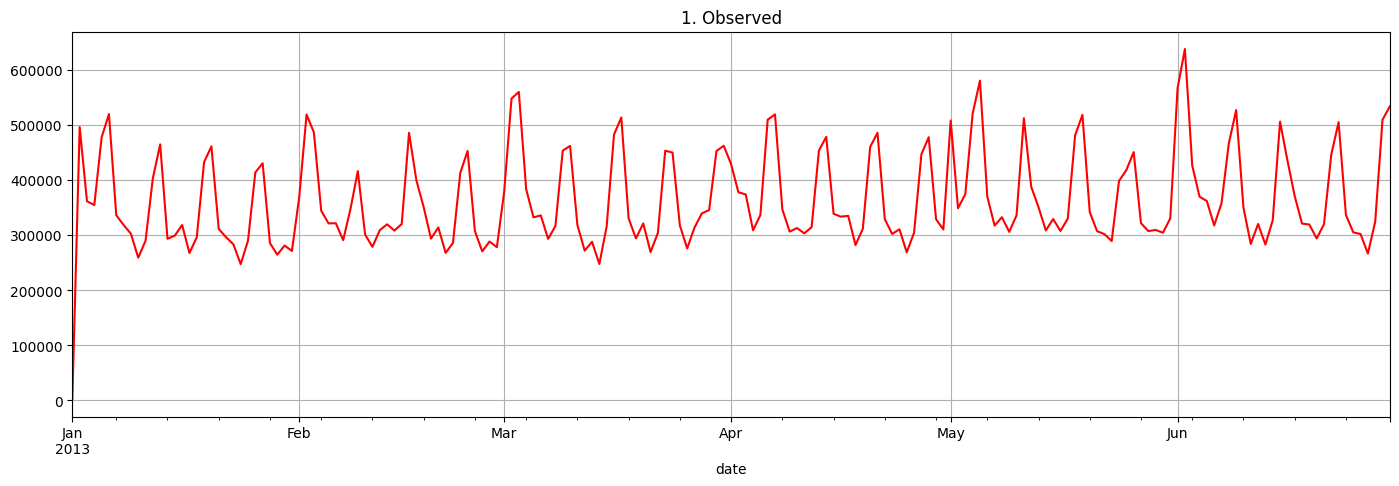

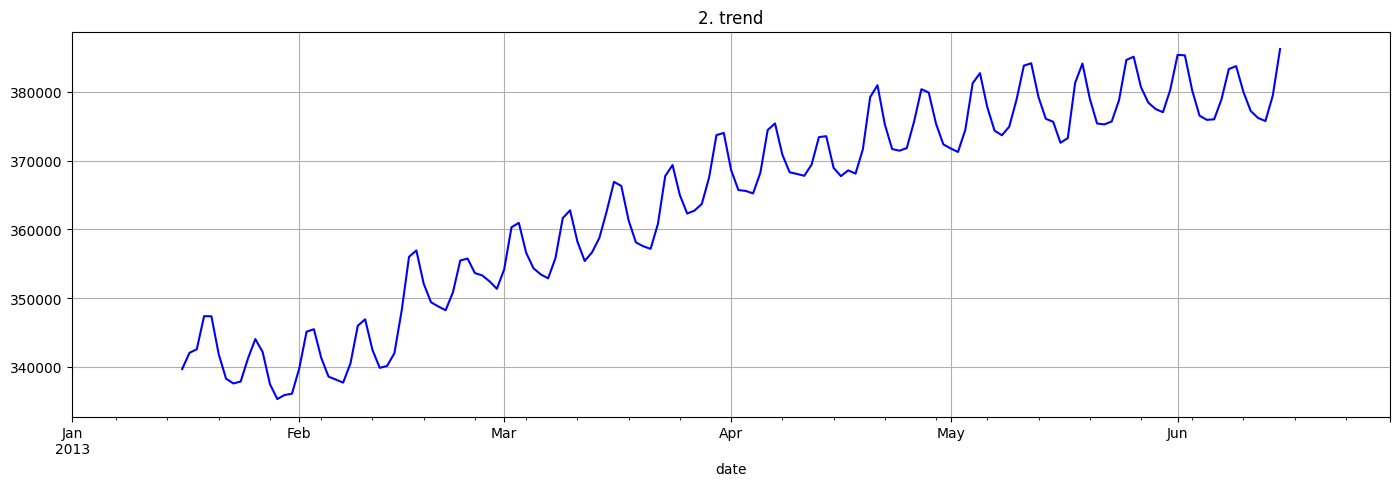

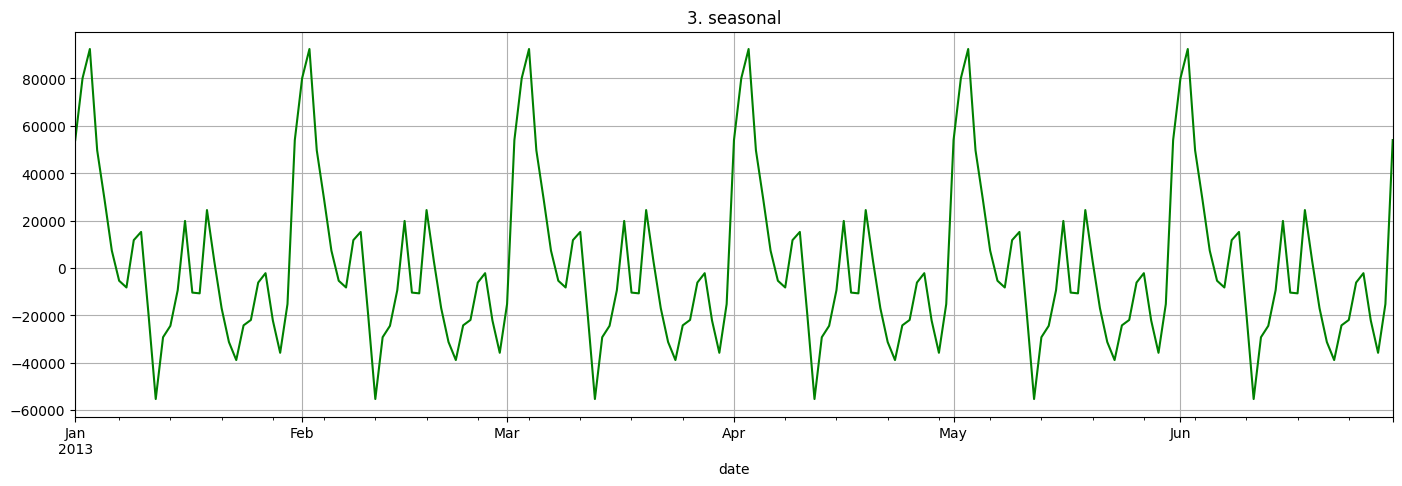

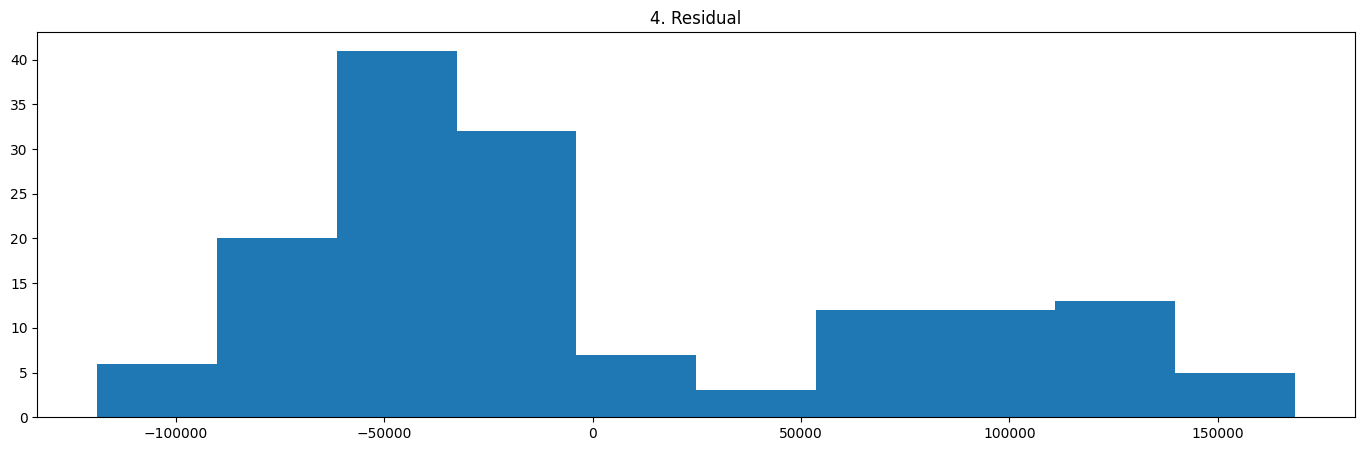

In [15]:
compos = time_split(data=df_store, start_date="2013-01-01", end_date="2013-06-30", period=30)

fig = plt.figure(figsize=(17, 5))
compos.observed.plot(color="red")
plt.title("1. Observed")
plt.grid()
plt.show()

fig = plt.figure(figsize=(17, 5))
compos.trend.plot(color="blue")
plt.title("2. trend")
plt.grid()
plt.show()

fig = plt.figure(figsize=(17, 5))
compos.seasonal.plot(color="green")
plt.title("3. seasonal")
plt.grid()
plt.show()

fig = plt.figure(figsize=(17, 5))
compos.resid.hist()
plt.title("4. Residual")
plt.grid()
plt.show()

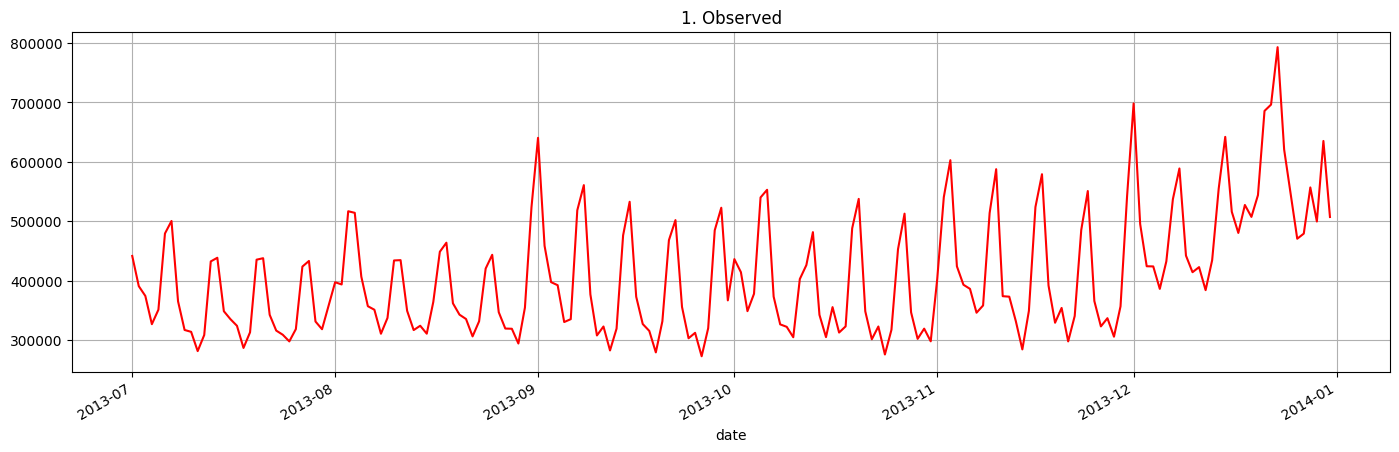

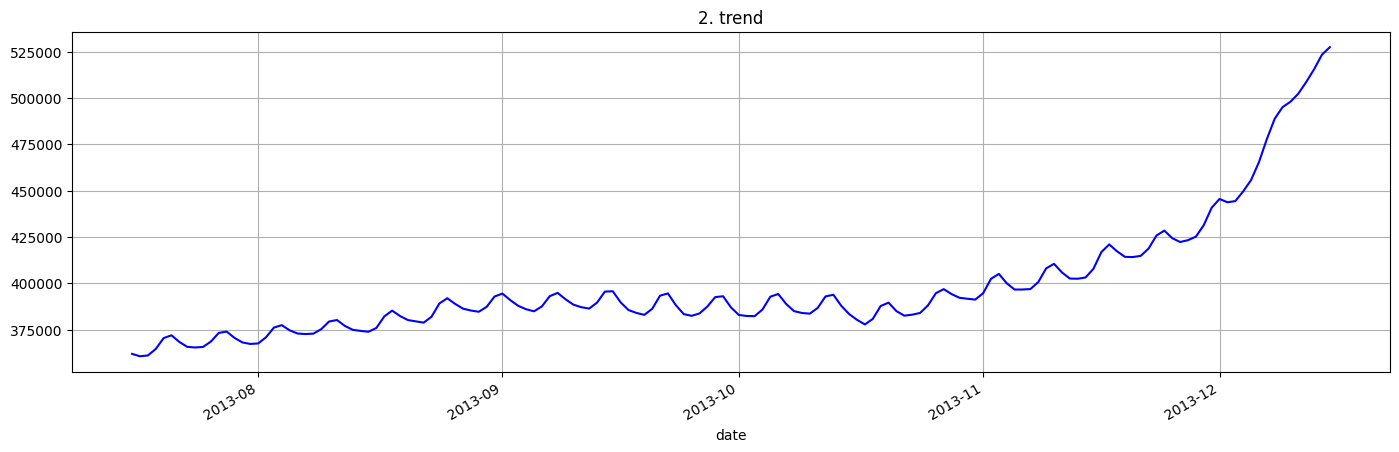

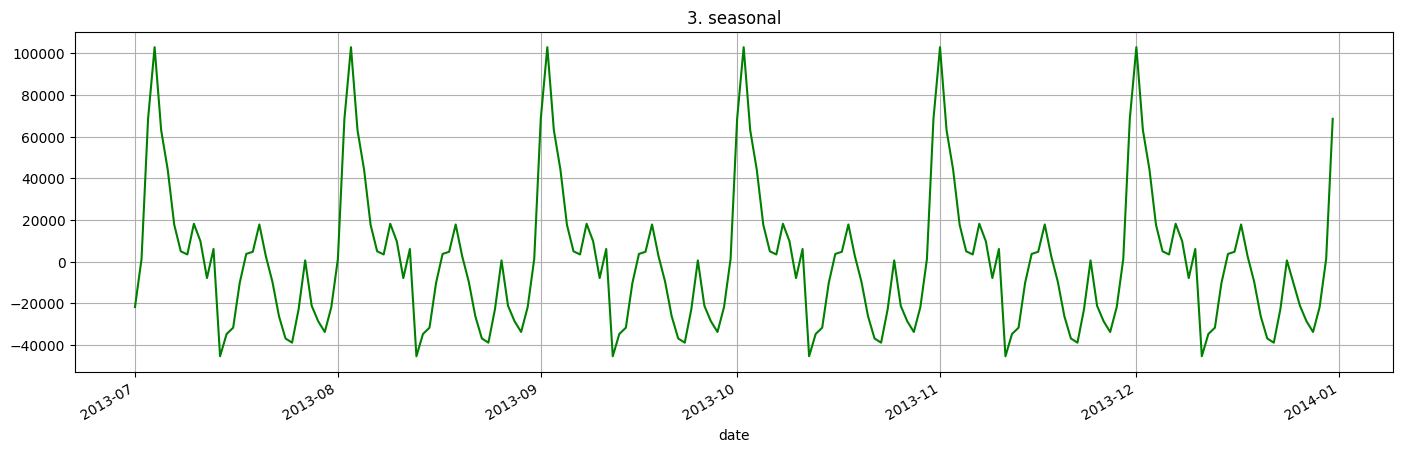

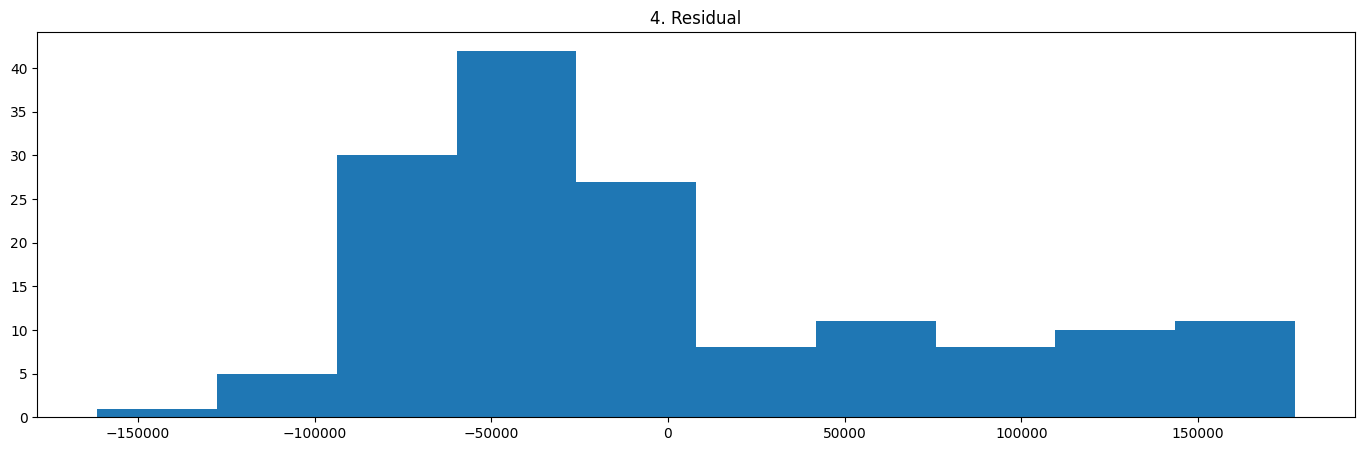

In [16]:
compos = time_split(data=df_store, start_date="2013-07-01", end_date="2013-12-31", period=30)

fig = plt.figure(figsize=(17, 5))
compos.observed.plot(color="red")
plt.title("1. Observed")
plt.grid()
plt.show()

fig = plt.figure(figsize=(17, 5))
compos.trend.plot(color="blue")
plt.title("2. trend")
plt.grid()
plt.show()

fig = plt.figure(figsize=(17, 5))
compos.seasonal.plot(color="green")
plt.title("3. seasonal")
plt.grid()
plt.show()

fig = plt.figure(figsize=(17, 5))
compos.resid.hist()
plt.title("4. Residual")
plt.grid()
plt.show()

## Analysis of 2014 Time Series Components
- 2014-01-01 / 2014-12-31

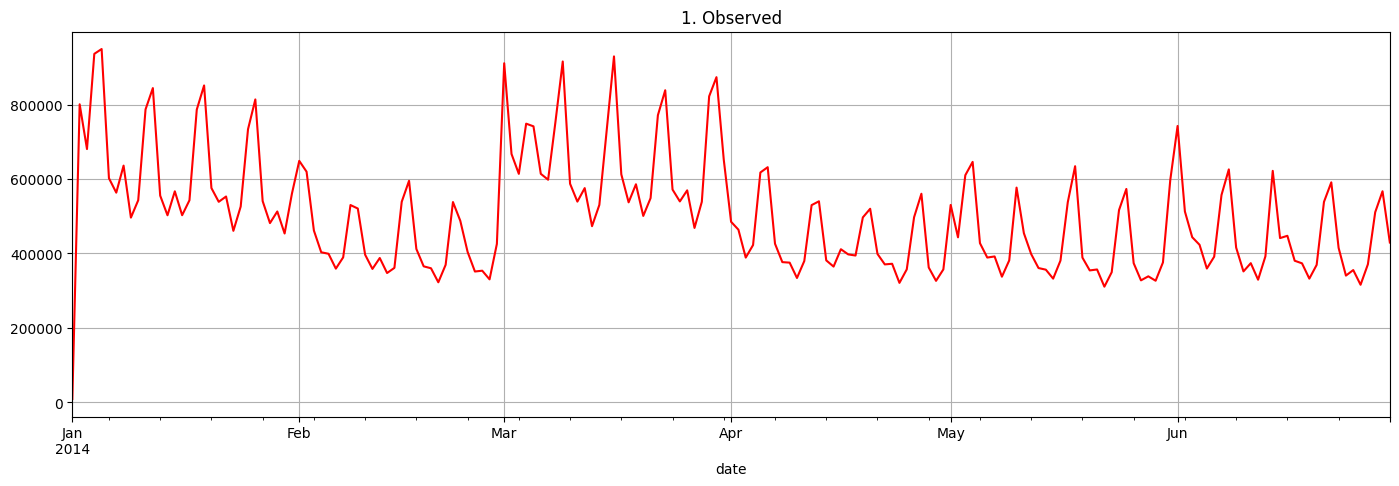

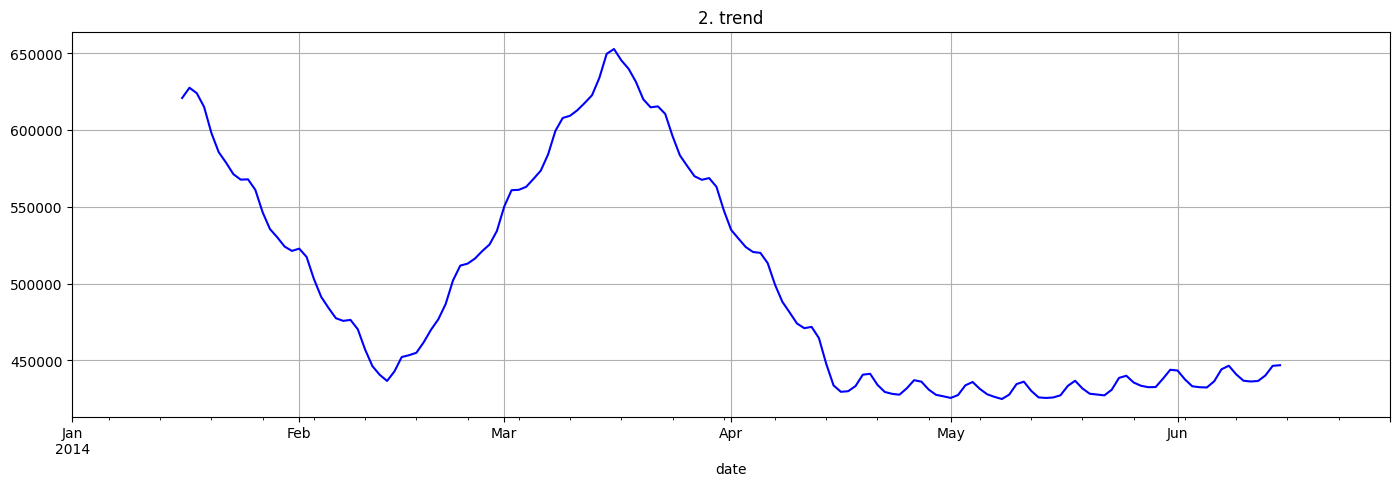

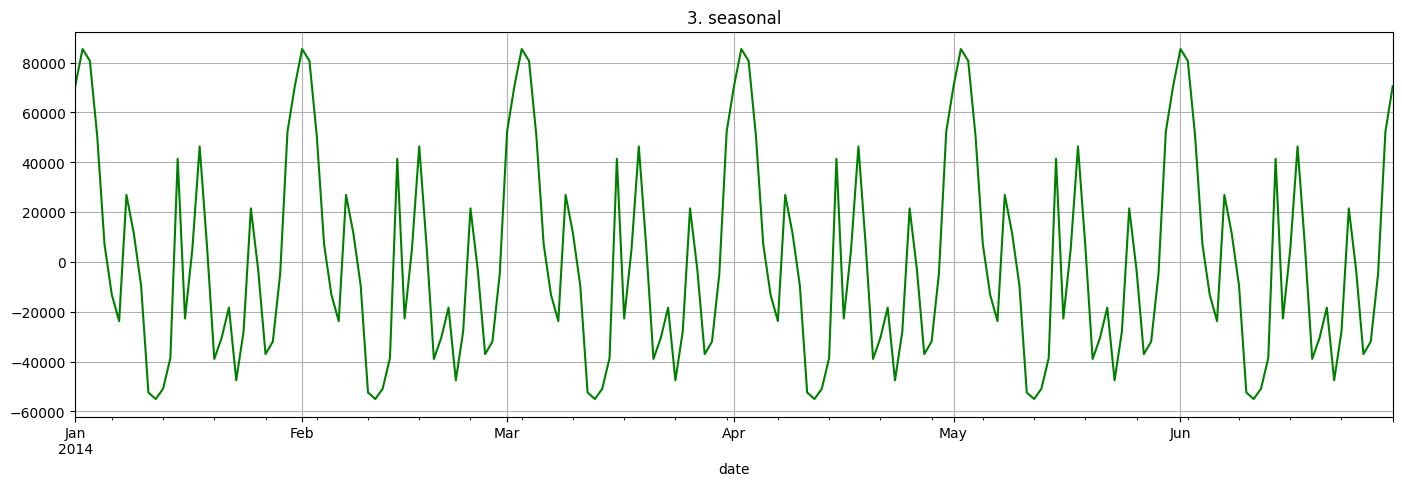

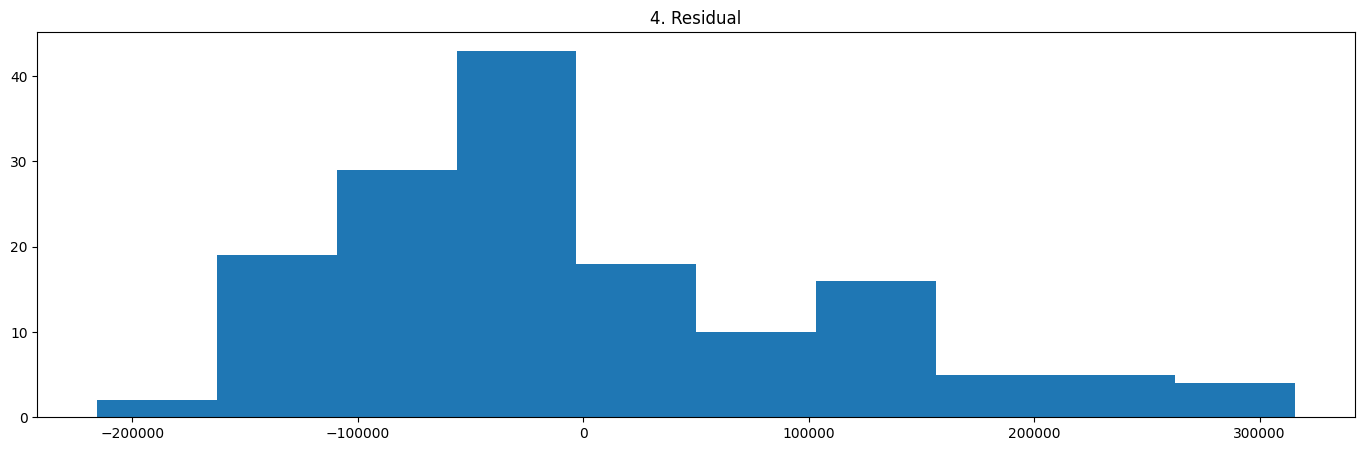

In [17]:
compos = time_split(data=df_store, start_date="2014-01-01", end_date="2014-06-30", period=30)

fig = plt.figure(figsize=(17, 5))
compos.observed.plot(color="red")
plt.title("1. Observed")
plt.grid()
plt.show()

fig = plt.figure(figsize=(17, 5))
compos.trend.plot(color="blue")
plt.title("2. trend")
plt.grid()
plt.show()

fig = plt.figure(figsize=(17, 5))
compos.seasonal.plot(color="green")
plt.title("3. seasonal")
plt.grid()
plt.show()

fig = plt.figure(figsize=(17, 5))
compos.resid.hist()
plt.title("4. Residual")
plt.grid()
plt.show()

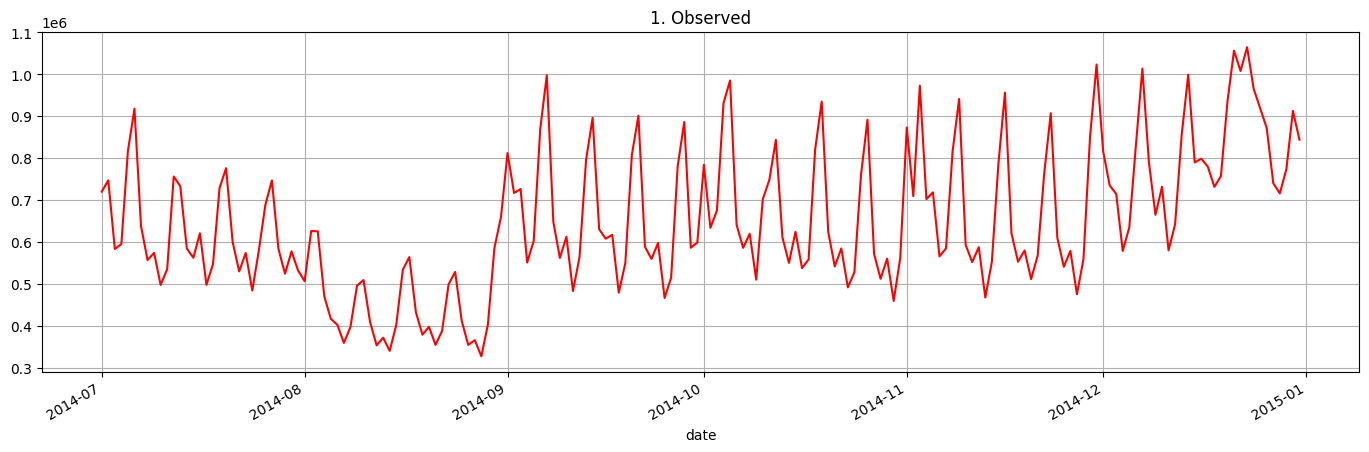

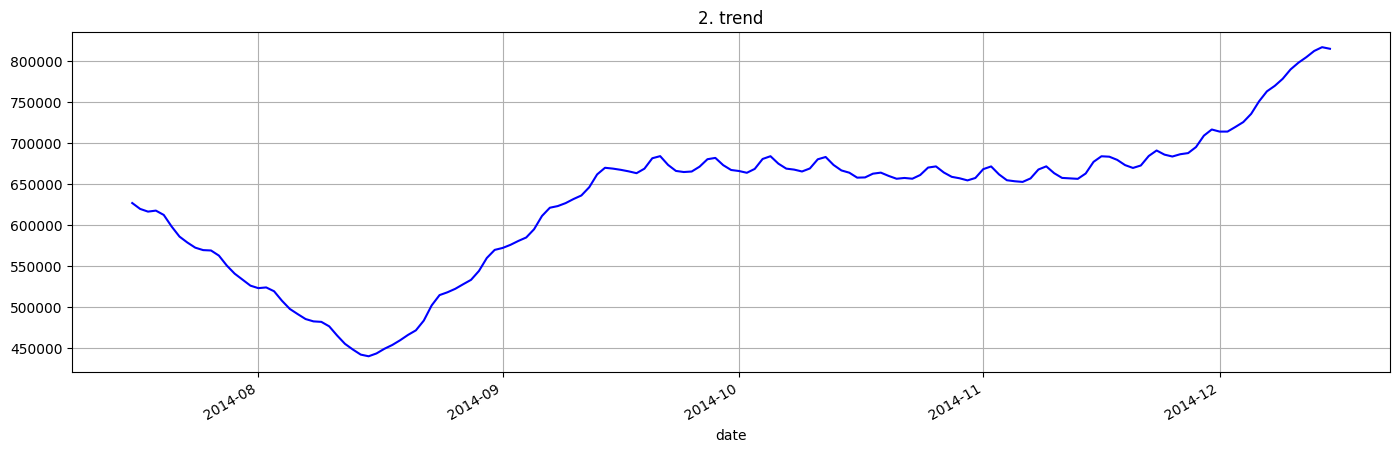

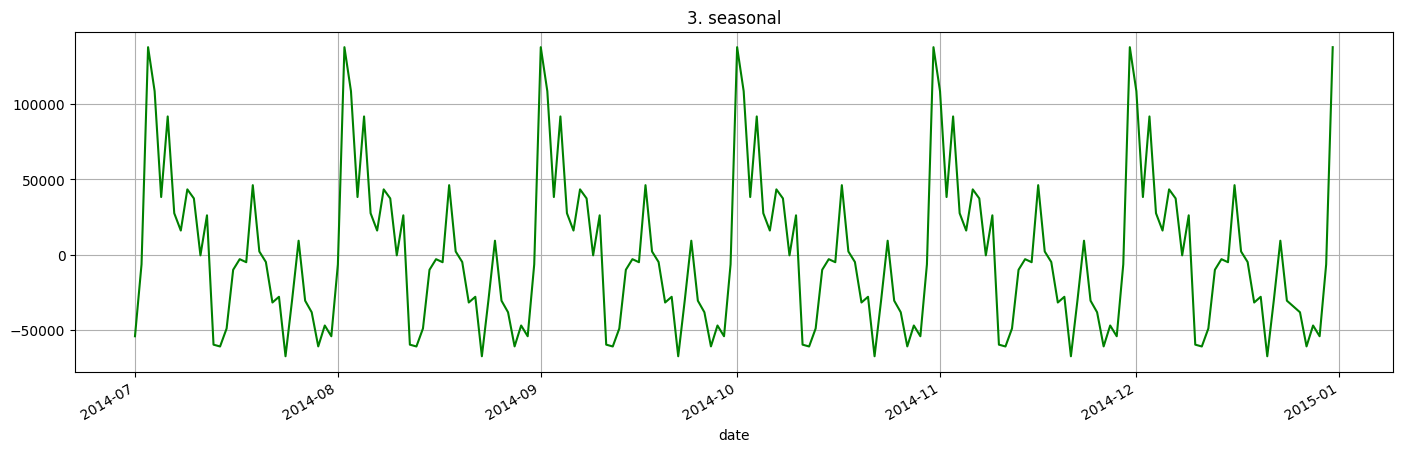

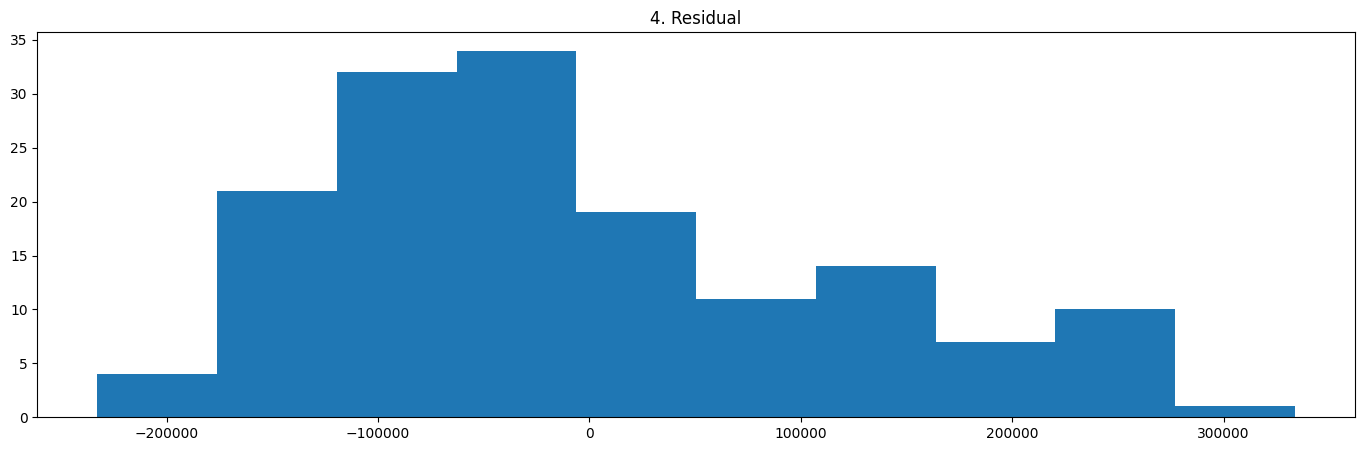

In [18]:
compos = time_split(data=df_store, start_date="2014-07-01", end_date="2014-12-31", period=30)

fig = plt.figure(figsize=(17, 5))
compos.observed.plot(color="red")
plt.title("1. Observed")
plt.grid()
plt.show()

fig = plt.figure(figsize=(17, 5))
compos.trend.plot(color="blue")
plt.title("2. trend")
plt.grid()
plt.show()

fig = plt.figure(figsize=(17, 5))
compos.seasonal.plot(color="green")
plt.title("3. seasonal")
plt.grid()
plt.show()

fig = plt.figure(figsize=(17, 5))
compos.resid.hist()
plt.title("4. Residual")
plt.grid()
plt.show()

## Analysis of 2015 Time Series Components
- 2015-01-01 / 2015-12-31

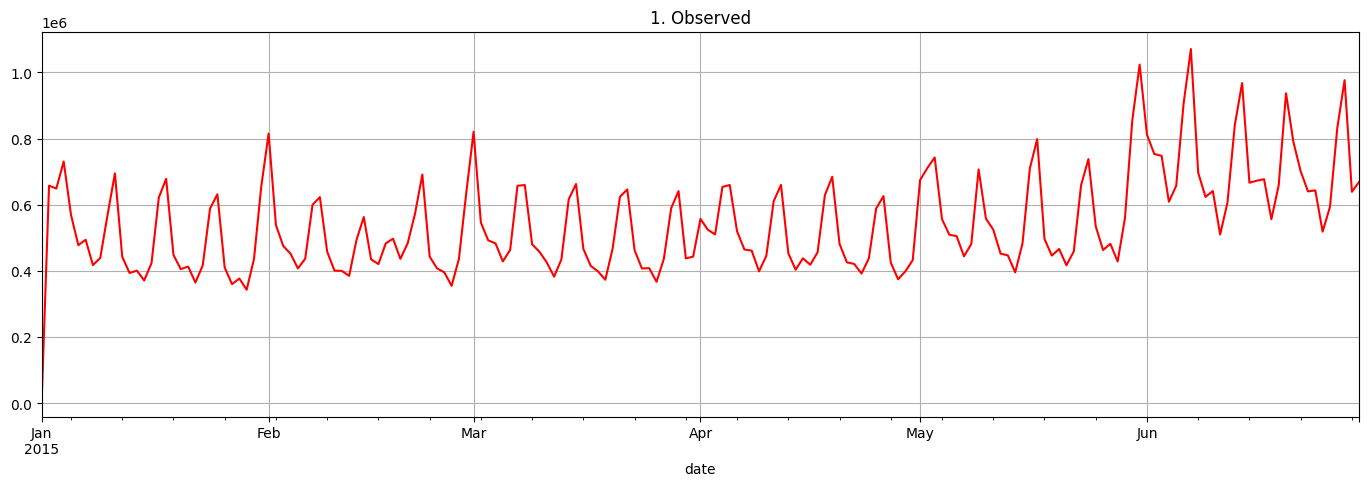

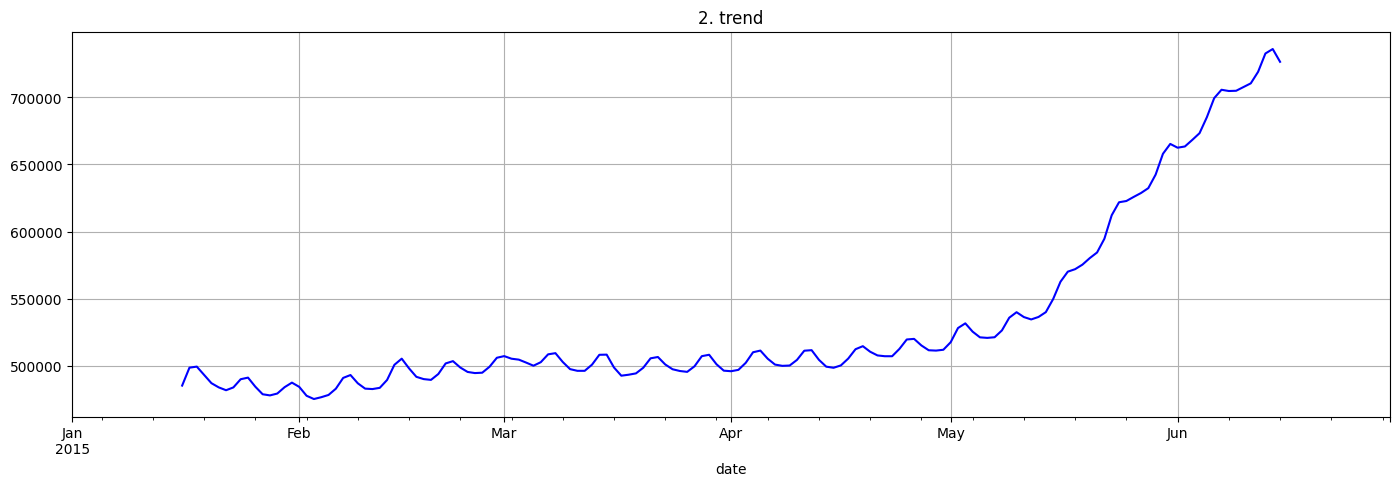

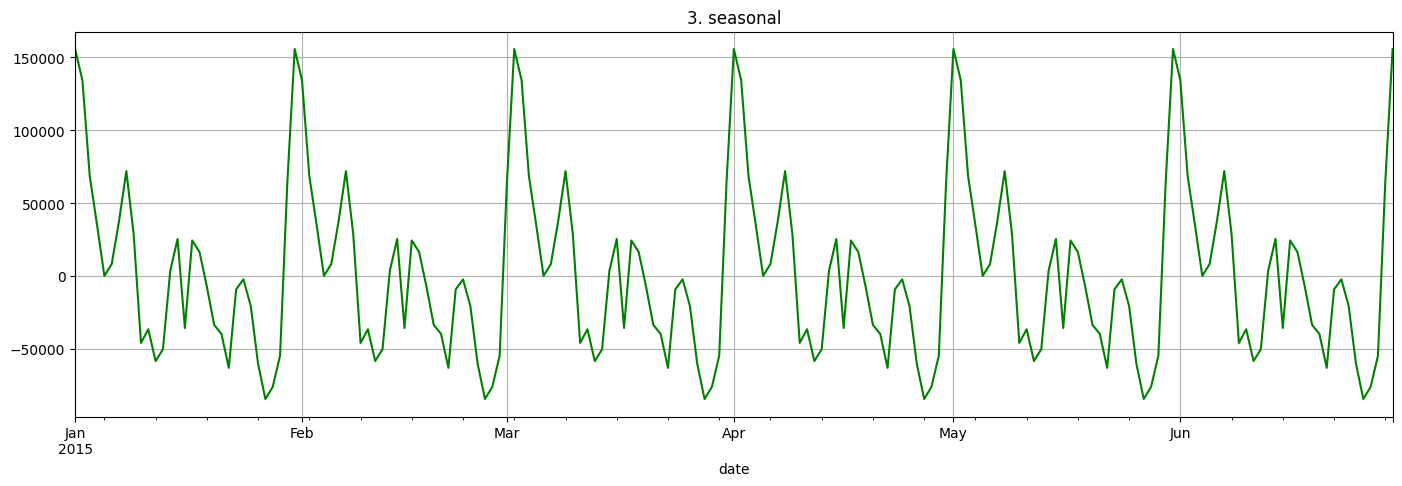

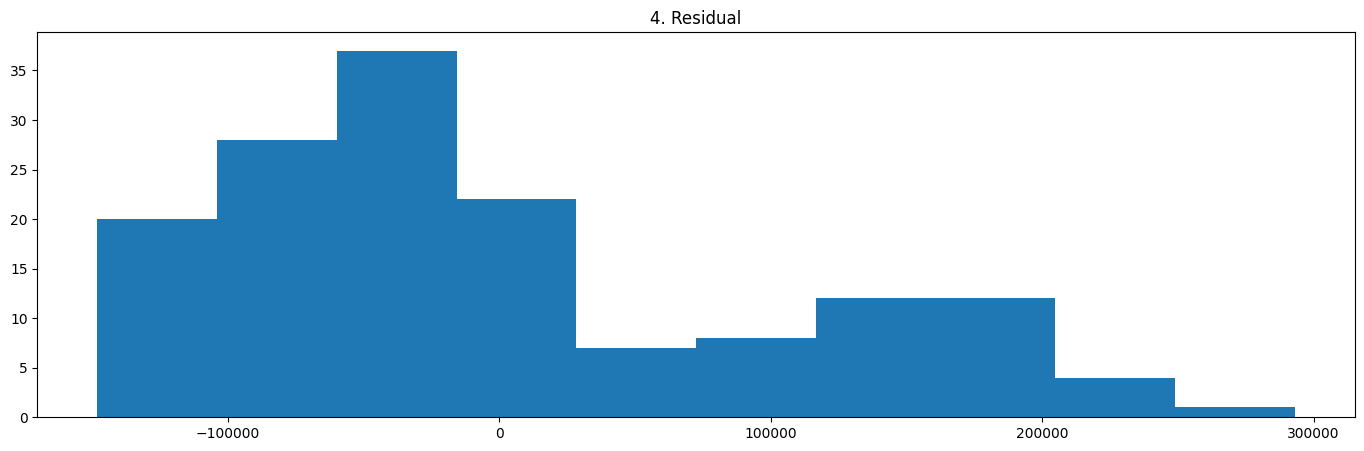

In [19]:
compos = time_split(data=df_store, start_date="2015-01-01", end_date="2015-06-30", period=30)

fig = plt.figure(figsize=(17, 5))
compos.observed.plot(color="red")
plt.title("1. Observed")
plt.grid()
plt.show()

fig = plt.figure(figsize=(17, 5))
compos.trend.plot(color="blue")
plt.title("2. trend")
plt.grid()
plt.show()

fig = plt.figure(figsize=(17, 5))
compos.seasonal.plot(color="green")
plt.title("3. seasonal")
plt.grid()
plt.show()

fig = plt.figure(figsize=(17, 5))
compos.resid.hist()
plt.title("4. Residual")
plt.grid()
plt.show()

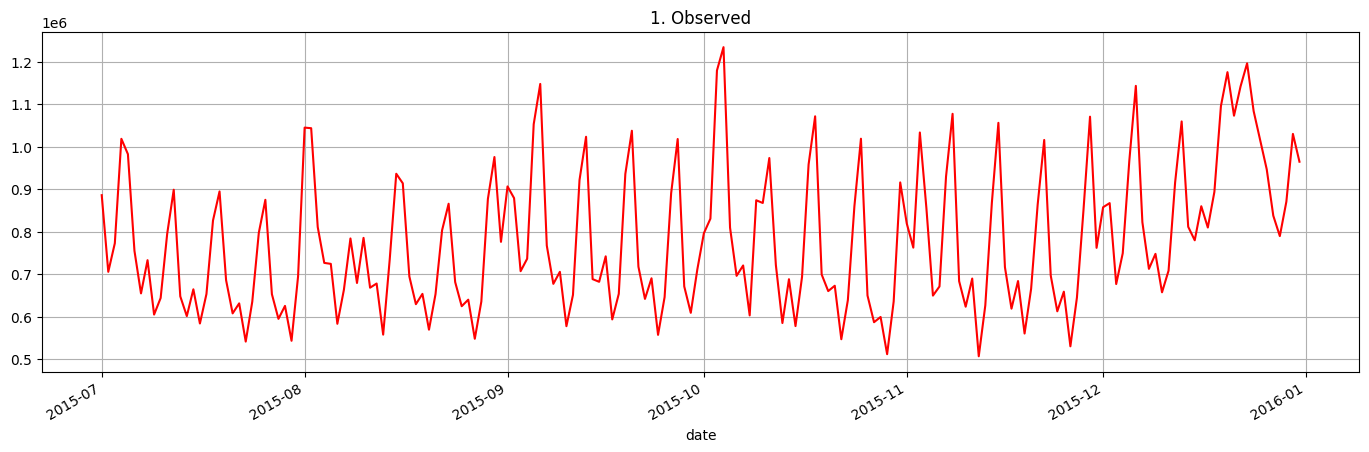

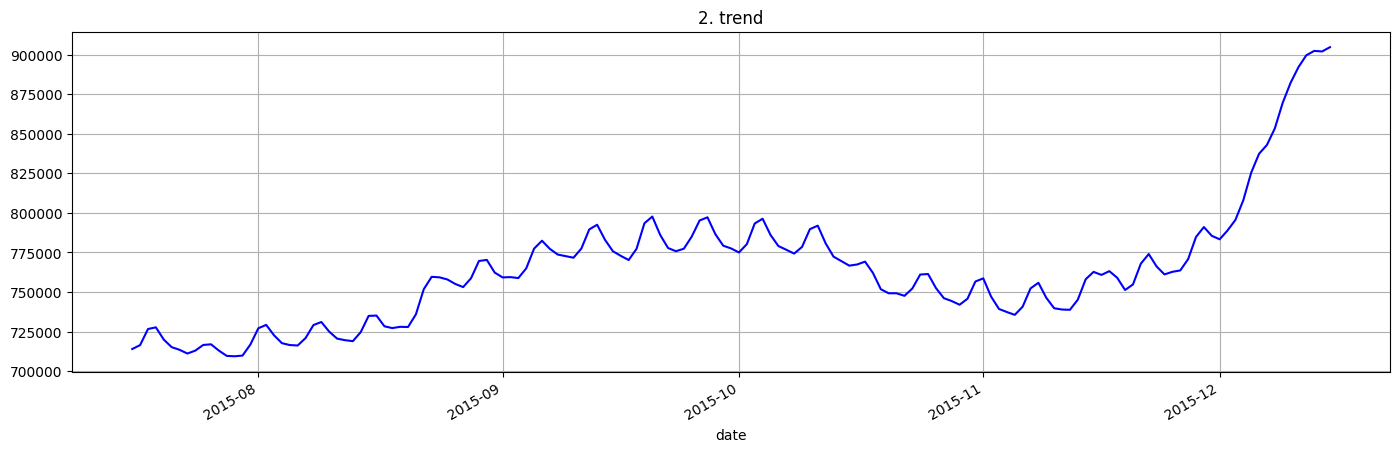

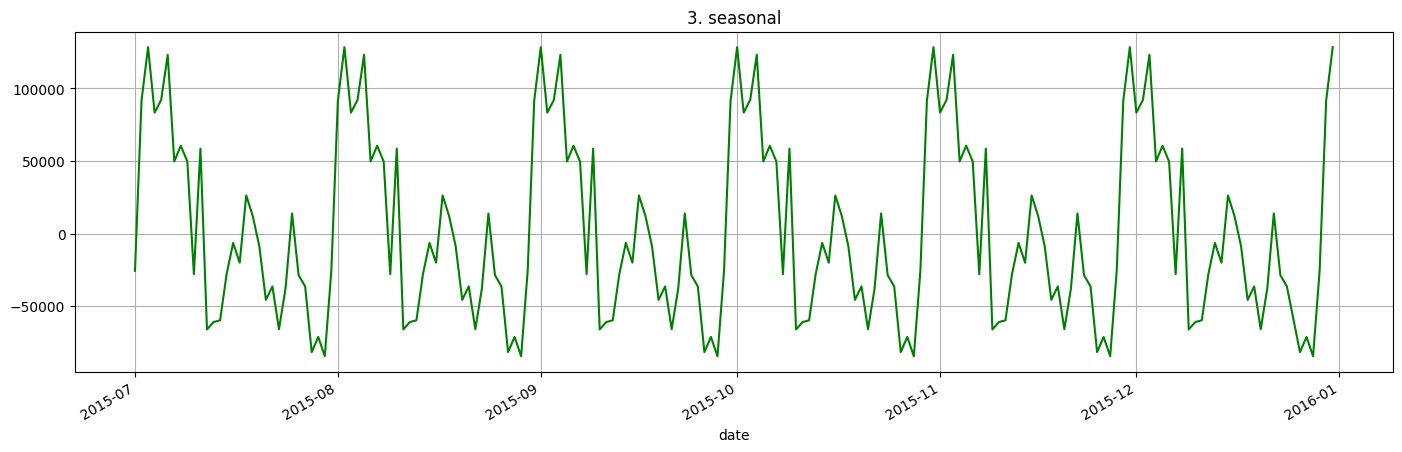

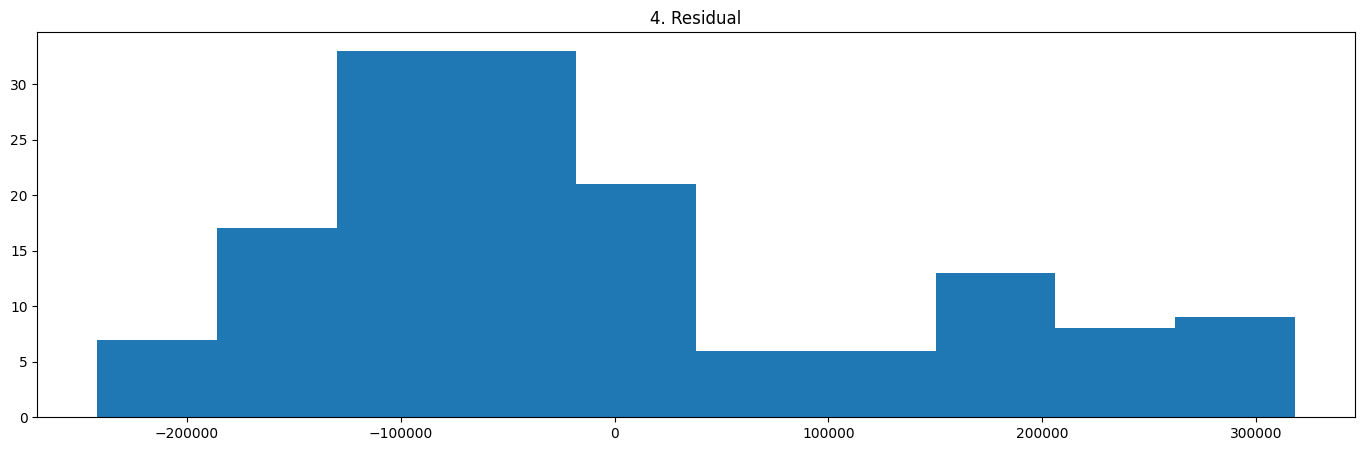

In [20]:
compos = time_split(data=df_store, start_date="2015-07-01", end_date="2015-12-31", period=30)

fig = plt.figure(figsize=(17, 5))
compos.observed.plot(color="red")
plt.title("1. Observed")
plt.grid()
plt.show()

fig = plt.figure(figsize=(17, 5))
compos.trend.plot(color="blue")
plt.title("2. trend")
plt.grid()
plt.show()

fig = plt.figure(figsize=(17, 5))
compos.seasonal.plot(color="green")
plt.title("3. seasonal")
plt.grid()
plt.show()

fig = plt.figure(figsize=(17, 5))
compos.resid.hist()
plt.title("4. Residual")
plt.grid()
plt.show()

## Analysis of 2016 Time Series Components
- 2016-01-01 / 2016-12-31

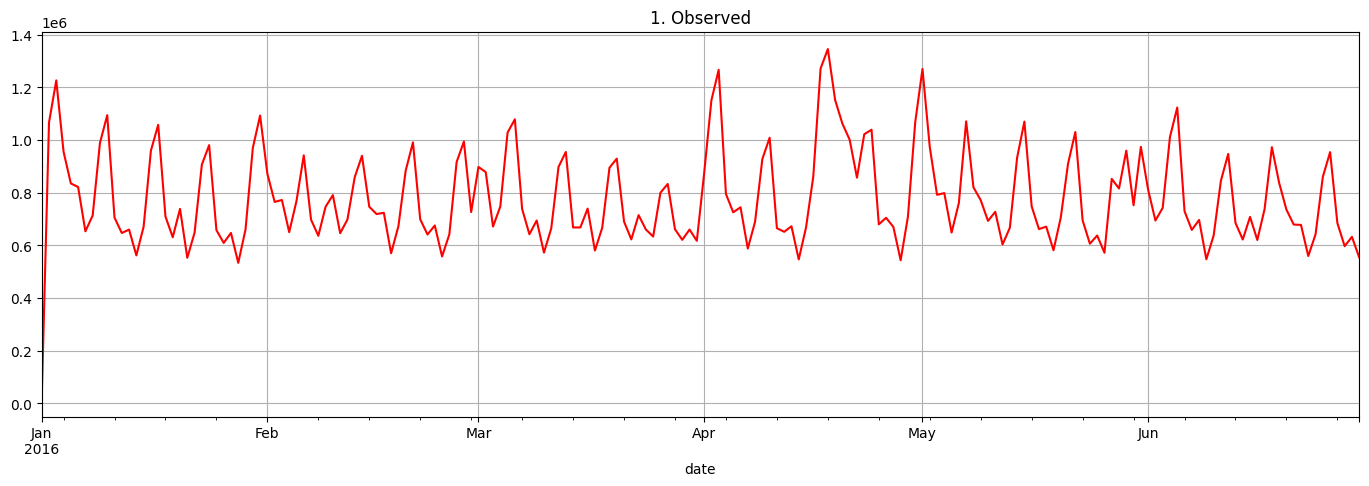

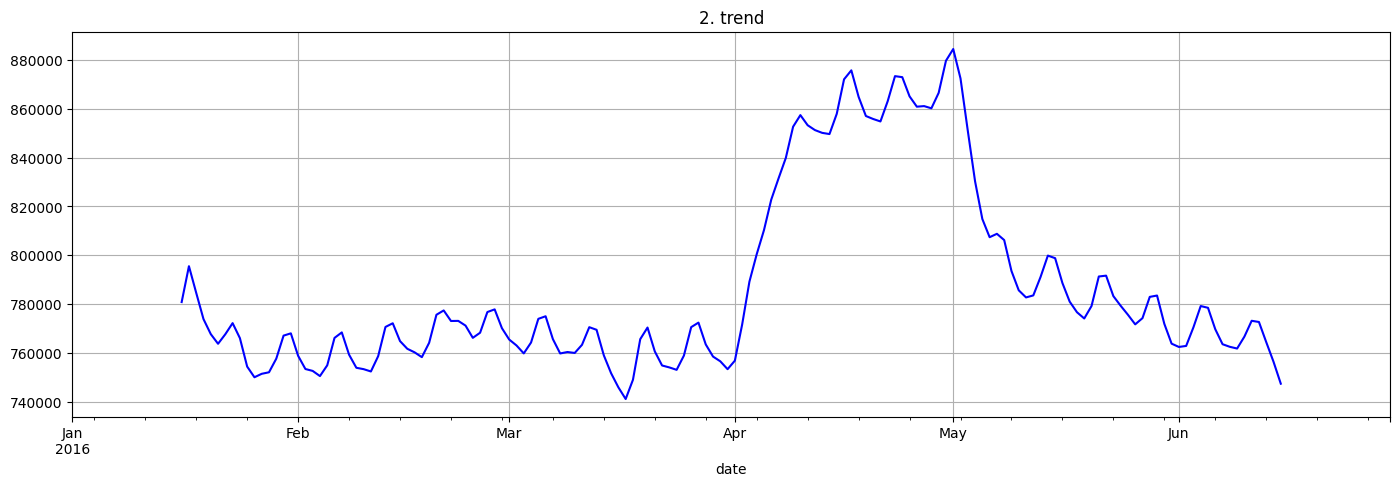

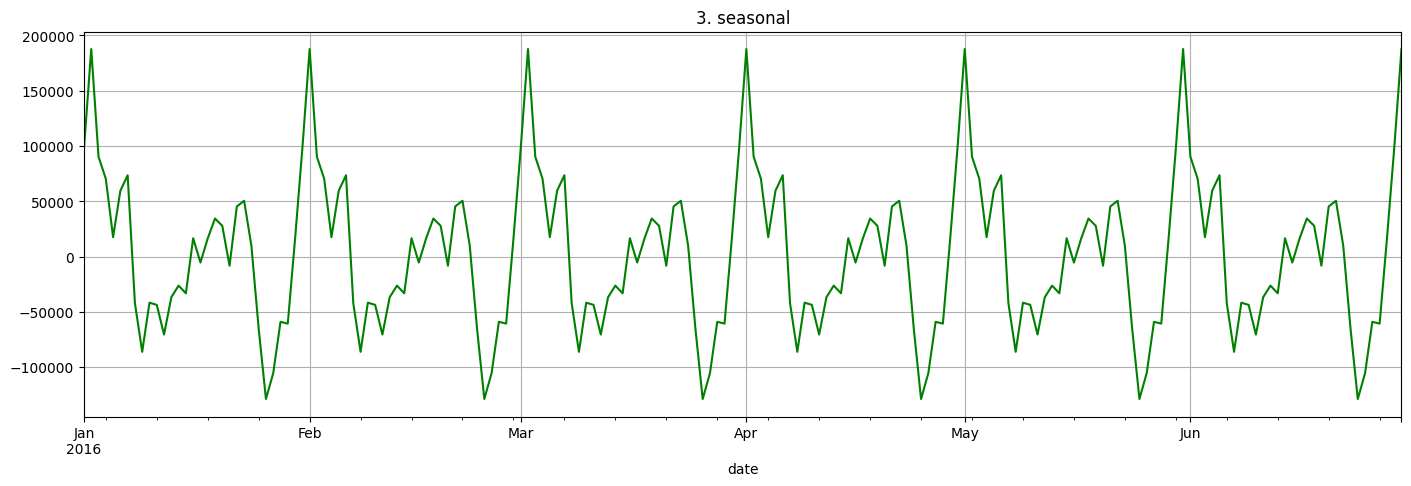

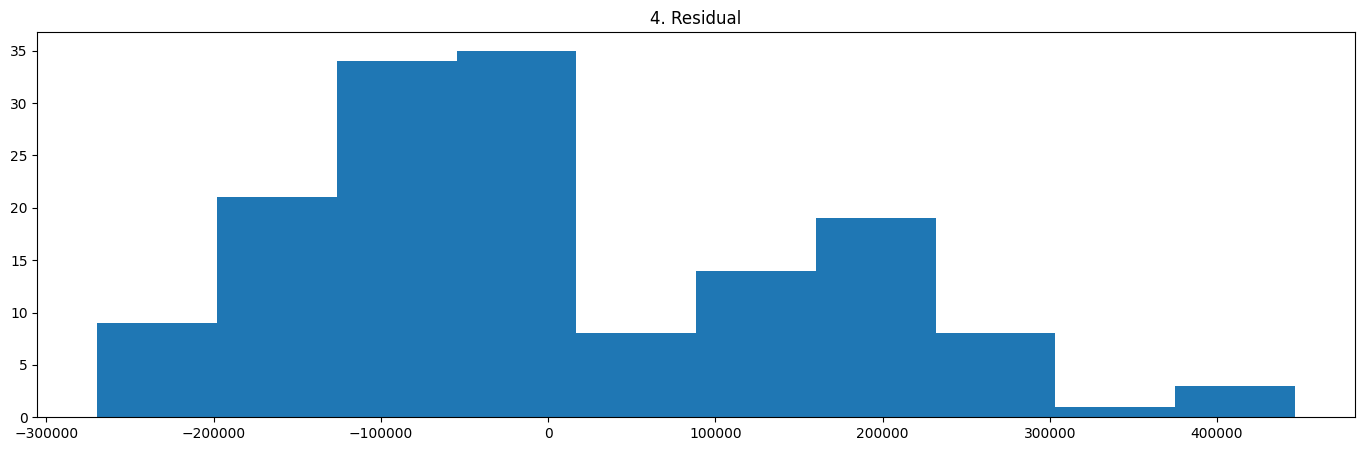

In [21]:
compos = time_split(data=df_store, start_date="2016-01-01", end_date="2016-06-30", period=30)

fig = plt.figure(figsize=(17, 5))
compos.observed.plot(color="red")
plt.title("1. Observed")
plt.grid()
plt.show()

fig = plt.figure(figsize=(17, 5))
compos.trend.plot(color="blue")
plt.title("2. trend")
plt.grid()
plt.show()

fig = plt.figure(figsize=(17, 5))
compos.seasonal.plot(color="green")
plt.title("3. seasonal")
plt.grid()
plt.show()

fig = plt.figure(figsize=(17, 5))
compos.resid.hist()
plt.title("4. Residual")
plt.grid()
plt.show()

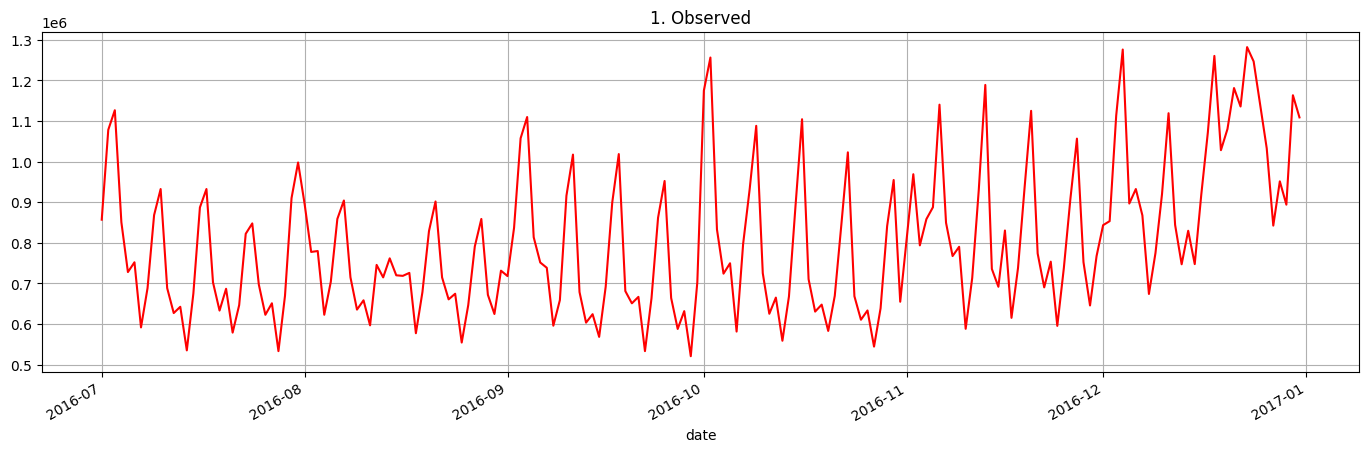

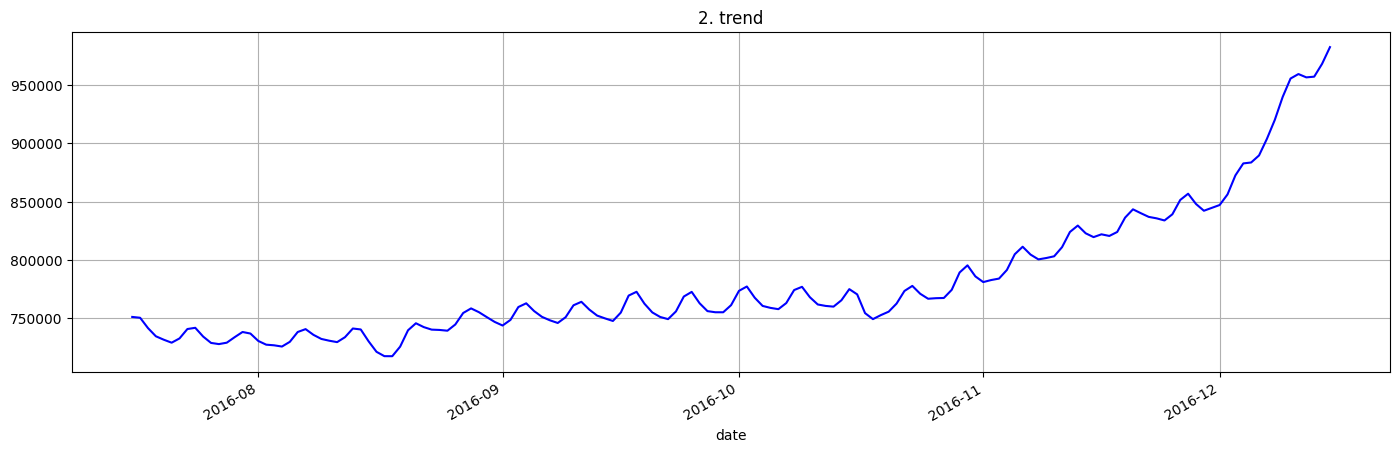

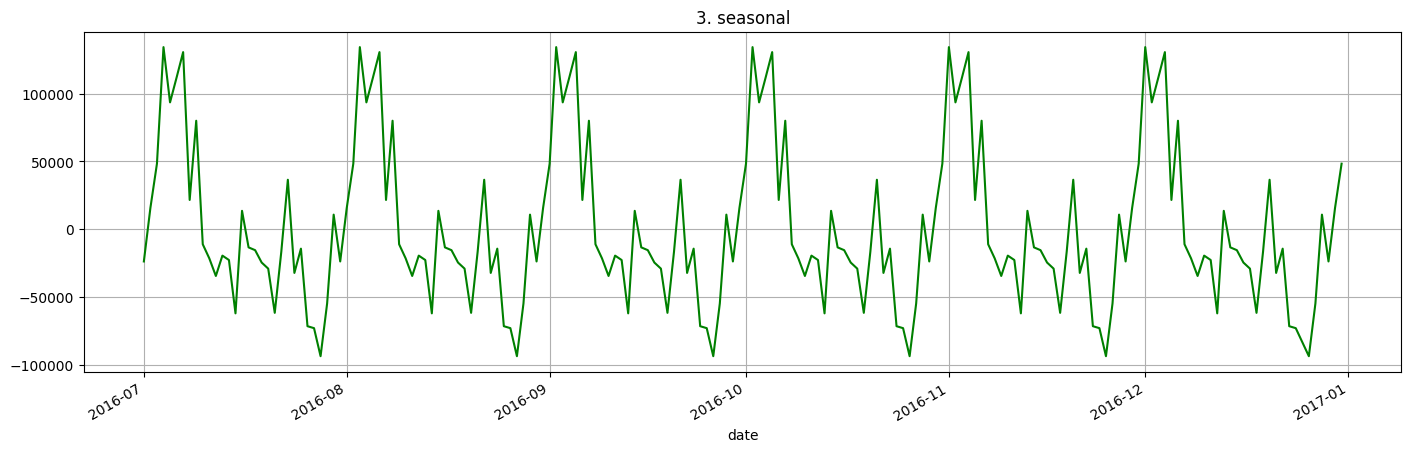

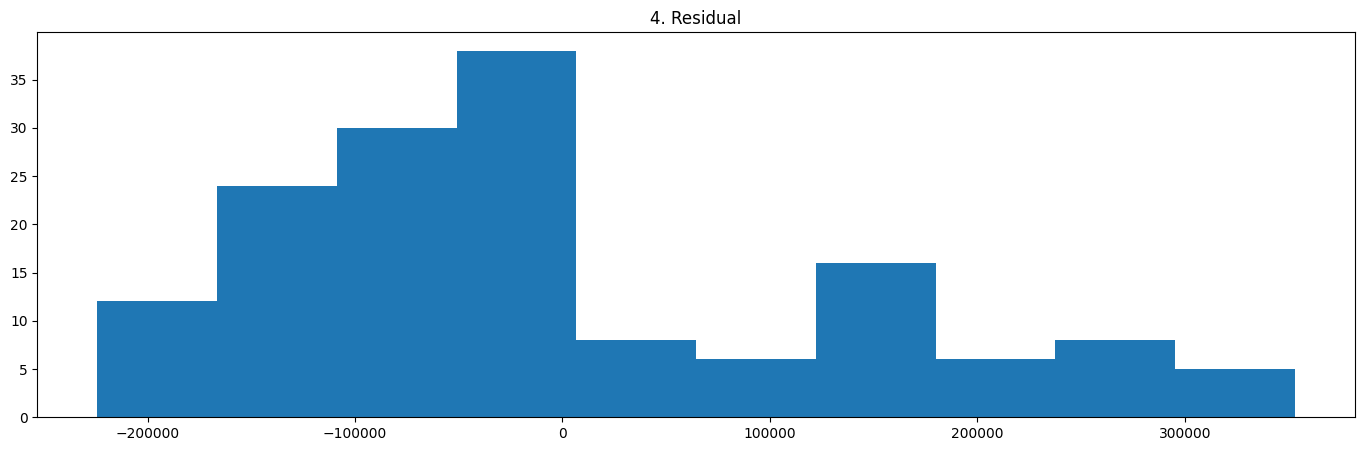

In [22]:
compos = time_split(data=df_store, start_date="2016-07-01", end_date="2016-12-31", period=30)

fig = plt.figure(figsize=(17, 5))
compos.observed.plot(color="red")
plt.title("1. Observed")
plt.grid()
plt.show()

fig = plt.figure(figsize=(17, 5))
compos.trend.plot(color="blue")
plt.title("2. trend")
plt.grid()
plt.show()

fig = plt.figure(figsize=(17, 5))
compos.seasonal.plot(color="green")
plt.title("3. seasonal")
plt.grid()
plt.show()

fig = plt.figure(figsize=(17, 5))
compos.resid.hist()
plt.title("4. Residual")
plt.grid()
plt.show()

## Analysis of 2017 Time Series Components
- 2017-01-01 / 2017-12-31

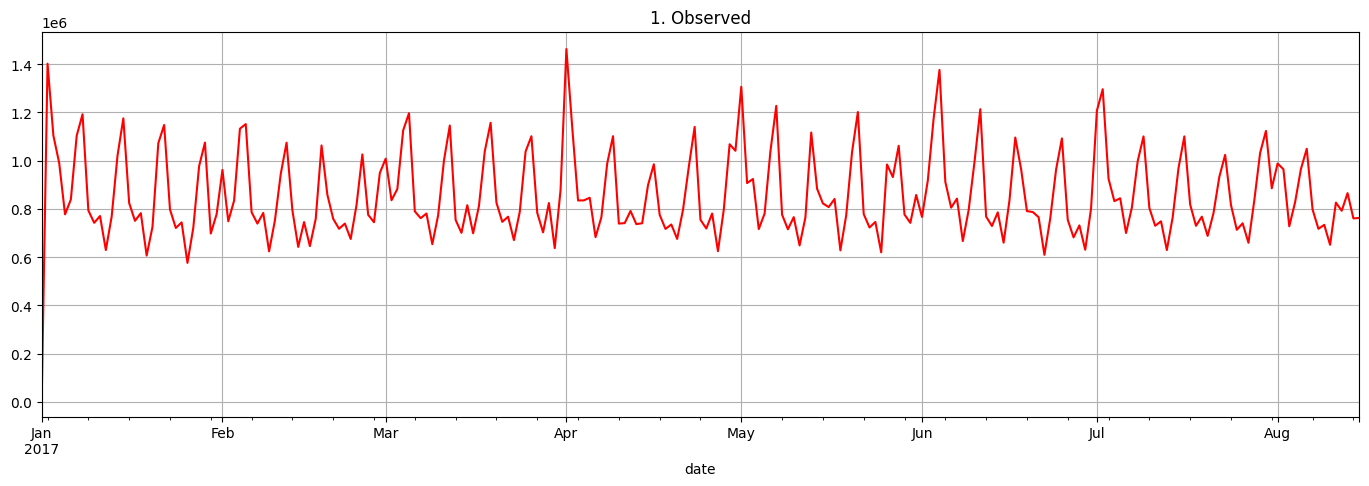

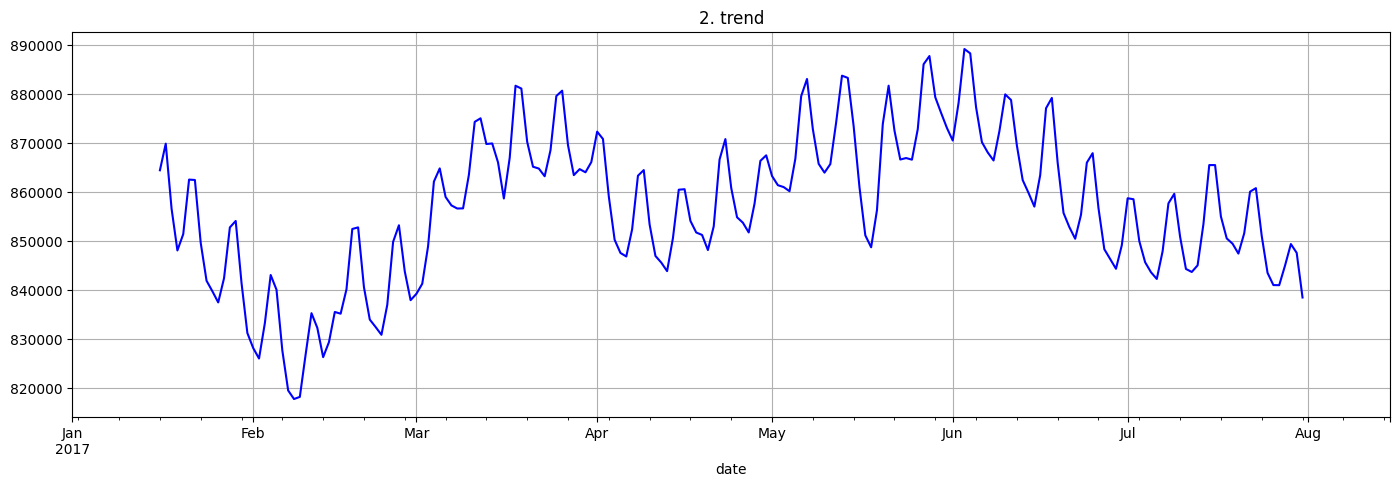

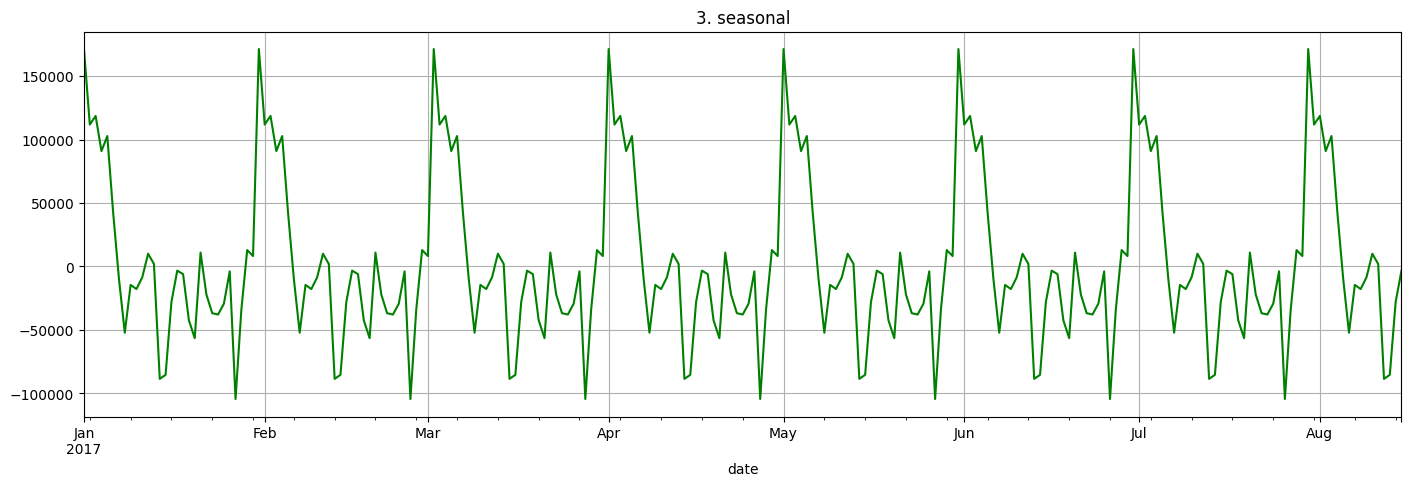

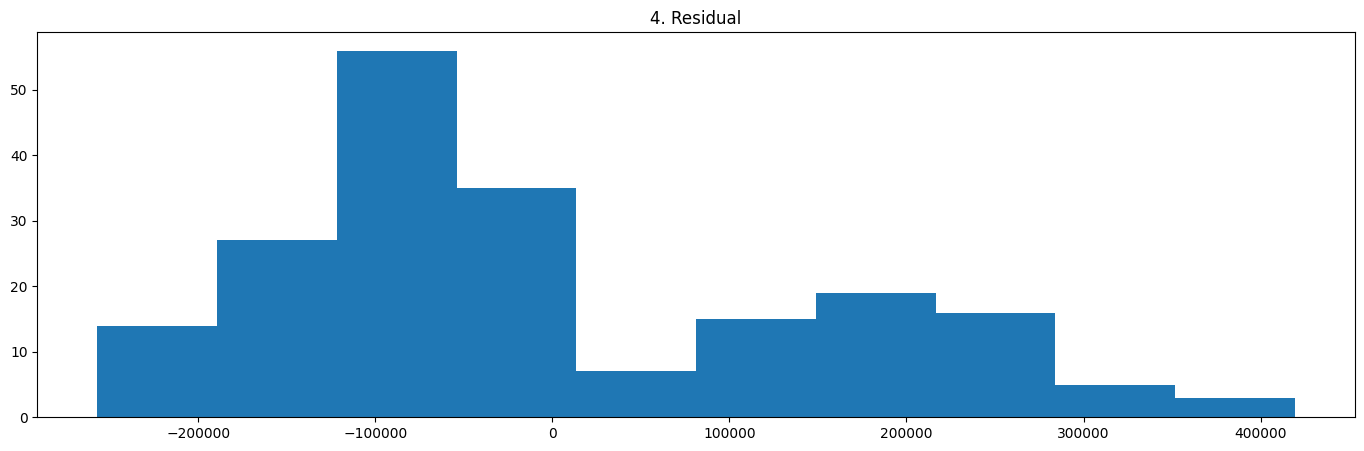

In [23]:
compos = time_split(data=df_store, start_date="2017-01-01", end_date="2017-08-15", period=30)

fig = plt.figure(figsize=(17, 5))
compos.observed.plot(color="red")
plt.title("1. Observed")
plt.grid()
plt.show()

fig = plt.figure(figsize=(17, 5))
compos.trend.plot(color="blue")
plt.title("2. trend")
plt.grid()
plt.show()

fig = plt.figure(figsize=(17, 5))
compos.seasonal.plot(color="green")
plt.title("3. seasonal")
plt.grid()
plt.show()

fig = plt.figure(figsize=(17, 5))
compos.resid.hist()
plt.title("4. Residual")
plt.grid()
plt.show()

## Target Analysis
1. **Analysis of the static (fixed) nature**
- DikkyFuller-test
2. **Target Distribusion**

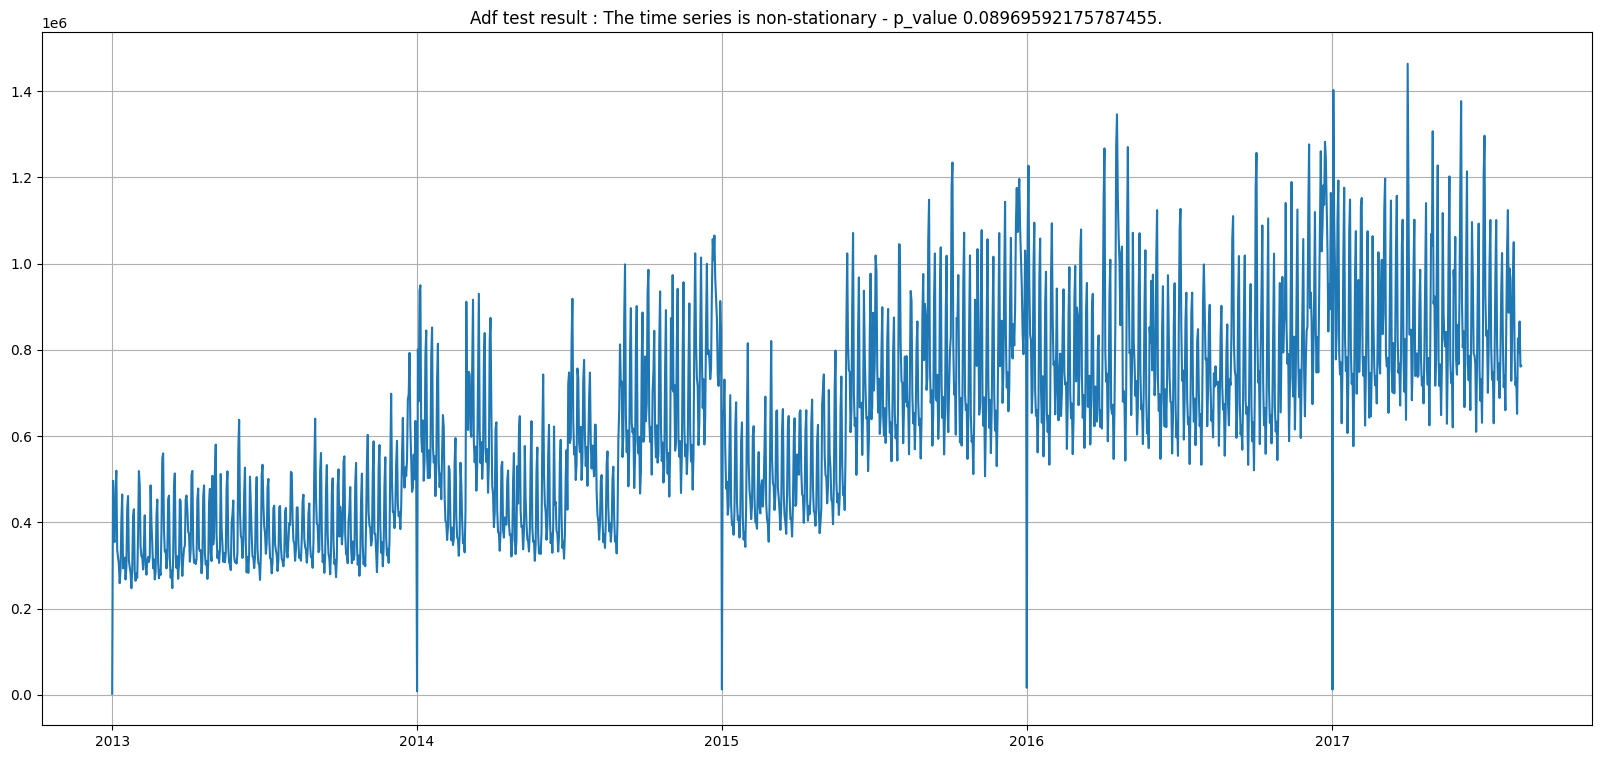

In [24]:
total_store = df_store.groupby("date")["sales"].sum()

adfuller_result = adfuller(total_store, autolag="AIC")

p_value = adfuller_result[1]

if p_value <= 0.05:
    plt.figure(figsize=(20, 9))
    plt.plot(total_store)
    plt.title(f"Adf test result : The time series is stationary - p_value {p_value}.")
    plt.grid()
    plt.show()
else:
    plt.figure(figsize=(20, 9))
    plt.plot(total_store)
    plt.title(f"Adf test result : The time series is non-stationary - p_value {p_value}.")
    plt.grid()
    plt.show()

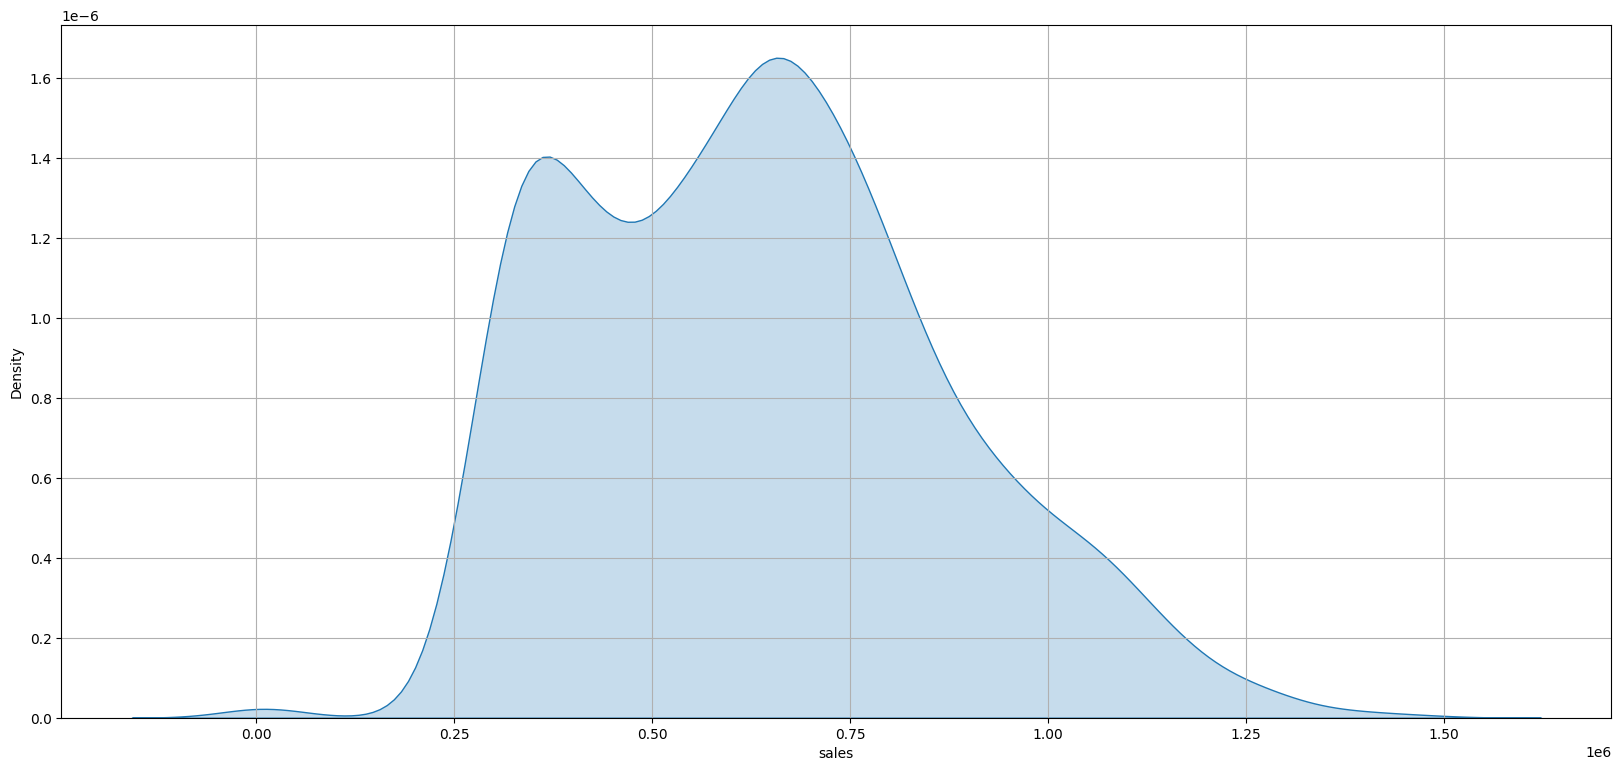

In [32]:
plt.figure(figsize=(20, 9))
sns.kdeplot(total_store, fill=True)
plt.grid()
plt.show()

## Feature Engineering

In [25]:
df_store["year"] = df_store["date"].dt.year
df_store["month"] = df_store["date"].dt.month
df_store["day"] = df_store["date"].dt.day
df_store['day_of_week'] = df_store['date'].dt.dayofweek
df_store["is_weekend"] = df_store['day_of_week'].isin([5, 6]).astype(int)
df_store["is_month_end"] = df_store["date"].dt.is_month_end.astype(int)

## Train Test Split
- Train >>> 2013-01-01 / 2016-12-31
- Test >>> 2017-01-01 / 2017-08-15

In [27]:
split_date = "2017-07-15"

train = df_store[df_store["date"] < split_date]
test = df_store[df_store["date"] >= split_date]

In [28]:
y_train = train["sales"].values.reshape(-1)

In [29]:
X_train = train.drop(columns=train[["date", "sales",]])

In [30]:
y_test = test["sales"].values.reshape(-1)

In [31]:
X_test = test.drop(columns=test[["date", "sales"]])

## Machine Learning PipeLine
- Preprocess : Missing Value, Scalling, Encoding
- Feature Selection : SelectFromModel
- Modeling : LGBMRegressor
- Evaluation : MAE, RMSE, R2

In [32]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

In [33]:
numeric_transform = Pipeline(steps=[
    ("MissingValue", SimpleImputer(strategy="median")),
    ("StandardScaler", StandardScaler()),
])

In [34]:
category_transform = Pipeline(steps=[
    ("MissingValue", SimpleImputer(strategy="most_frequent")),
    ("OneHotEncoder", OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])

In [44]:
numeric_list = ["onpromotion", "cluster", "month", "day", "day_of_week", "year"]
category_list = ["family", "city", "state", "type", "holiday", "is_weekend", "is_month_end", "store_nbr"]

In [45]:
preprocessor = ColumnTransformer(transformers=[
    ("num_transform", numeric_transform, numeric_list),
    ("cat_transform", category_transform, category_list)
])

In [46]:
pipeline_LGBM = Pipeline(steps=[
    ("Preprocess", preprocessor),
    ("Regressor", LGBMRegressor(n_estimators=200, metric=["tweedie"], objective="tweedie", tweedie_variance_power=1.2, learning_rate=0.3, random_state=1234))
])

In [47]:
pipeline_LGBM.fit(X_train, y_train)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.076630 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 551
[LightGBM] [Info] Number of data points in the train set: 2943864, number of used features: 142
[LightGBM] [Info] Start training from score 5.873569


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Preprocess', ...), ('Regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['store_nbr','family','onpromotion',...,'day_of_week','is_weekend', 'is_month_end']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_transform', ...), ('cat_transform', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically pass

In [48]:
y_pred_train = pipeline_LGBM.predict(X_train)
# ============================================
#  evaluation train
# ============================================
r2 = r2_score(y_train, y_pred_train)
mae = mean_absolute_error(y_train, y_pred_train)
rmse = root_mean_squared_error(y_train, y_pred_train)
print(f"R2 : {r2:.2f}")
print(f"MAE : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")

R2 : 0.96
MAE : 54.14
RMSE : 231.45


In [57]:
y_pred_test = np.round(pipeline_LGBM.predict(X_test), 0)
# ============================================
#  evaluation test
# ============================================
r2 = r2_score(y_test, y_pred_test)
mae = mean_absolute_error(y_test, y_pred_test)
rmse = root_mean_squared_error(y_test, y_pred_test)
print(f"R2 : {r2:.2f}")
print(f"MAE : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")

R2 : 0.96
MAE : 73.53
RMSE : 246.45


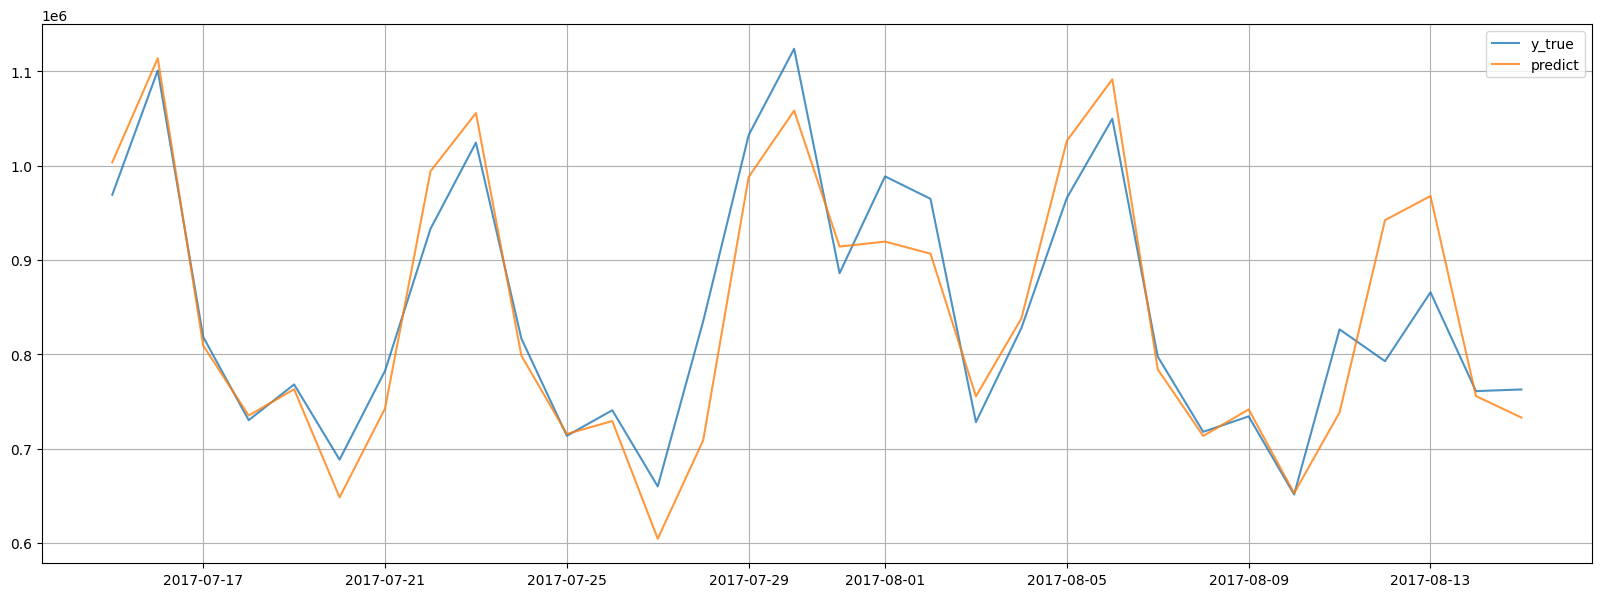

In [58]:
daily_actual = test.groupby("date")["sales"].sum()
df_daily_pred = pd.DataFrame({"date": test["date"], "pred": y_pred_test})
daily_pred = df_daily_pred.groupby("date")["pred"].sum()

plt.figure(figsize=(20, 7))
plt.plot(daily_actual.index, daily_actual.values, label="y_true", alpha=0.8)
plt.plot(daily_pred.index, daily_pred.values, label="predict", alpha=0.8)
plt.legend()
plt.grid()
plt.show()

In [59]:
y_pred_test

array([   5.,    0.,    8., ..., 2724.,   41.,   13.], shape=(57024,))

In [60]:
y_test

array([   6.   ,    0.   ,    5.   , ..., 2419.729,  121.   ,   16.   ],
      shape=(57024,))